ONCOLENS RESNET50 EXPERIMENT
Project root: c:\Users\Bhavana BV\Downloads\OncoLens
TensorFlow: 2.21.0
GPU devices: []
Split file: c:\Users\Bhavana BV\Downloads\OncoLens\split.csv

Available columns: ['path', 'label', 'w', 'h', 'md5', 'phash', 'group', 'split', 'label_id', 'use']

Split sizes:
Train: 1527
Validation: 328
Test: 325

Class counts by split:
label_binary    0    1
split                 
test          150  175
train         700  827
val           150  178

Groups crossing splits: 0


Model: "OncoLens_ResNet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocessing (Lambda)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_features (Dense) │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cancer_probability (Dense)      │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)


PHASE 1: TRAINING CLASSIFICATION HEAD
Epoch 1/8
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.8029 - auc: 0.8683 - loss: 0.4902
Epoch 1: val_loss improved from None to 0.32657, saving model to c:\Users\Bhavana BV\Downloads\OncoLens\results\resnet50_experiment\checkpoints\resnet50_best.keras

Epoch 1: finished saving model to c:\Users\Bhavana BV\Downloads\OncoLens\results\resnet50_experiment\checkpoints\resnet50_best.keras
96/96 ━━━━━━━━━━━━━━━━━━━━ 47s 460ms/step - accuracy: 0.8029 - auc: 0.8683 - loss: 0.4902 - val_accuracy: 0.8659 - val_auc: 0.9453 - val_loss: 0.3266 - learning_rate: 0.0010
Epoch 2/8
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step - accuracy: 0.8906 - auc: 0.9585 - loss: 0.2582
Epoch 2: val_loss improved from 0.32657 to 0.28032, saving model to c:\Users\Bhavana BV\Downloads\OncoLens\results\resnet50_experiment\checkpoints\resnet50_best.keras

Epoch 2: finished saving model to c:\Users\Bhavana BV\Downloads\OncoLens\results\resnet50_experiment\checkpoints\resnet50_b

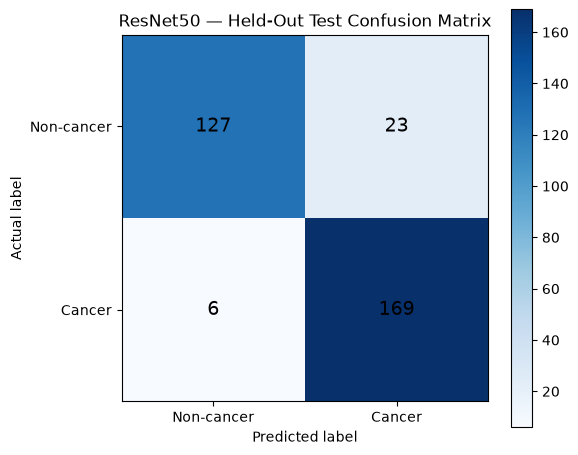

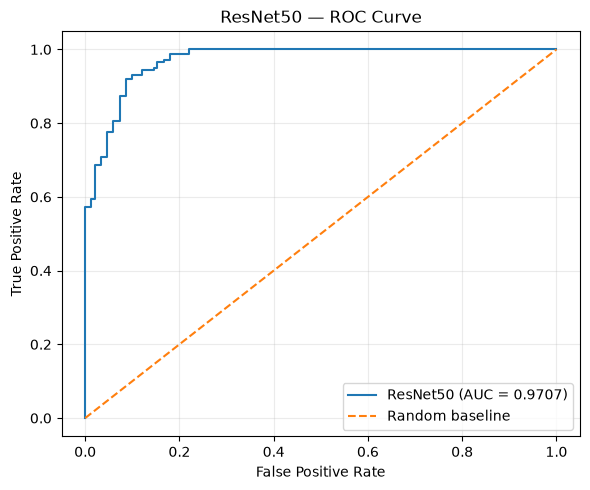

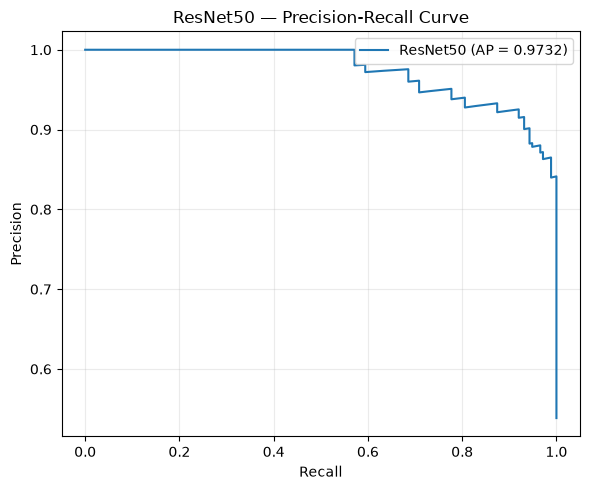

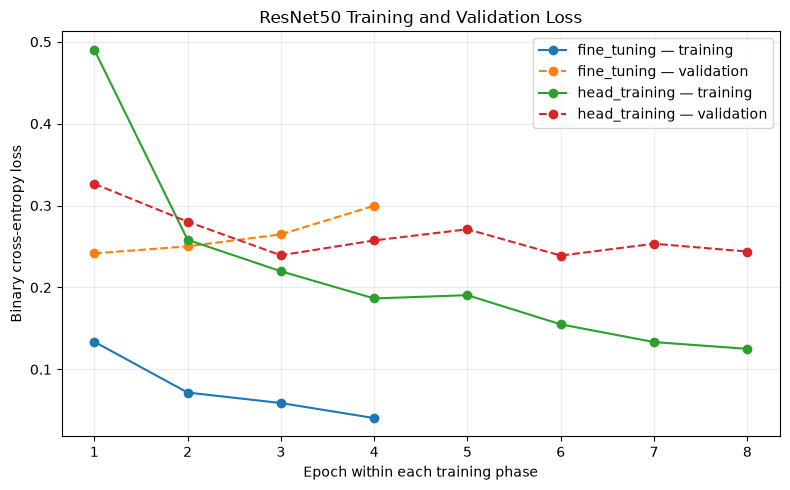


RESNET50 EXPERIMENT COMPLETED
Saved model: c:\Users\Bhavana BV\Downloads\OncoLens\results\resnet50_experiment\checkpoints\resnet50_best.keras
Metrics: c:\Users\Bhavana BV\Downloads\OncoLens\results\resnet50_experiment\resnet50_final_test_metrics.csv
Predictions: c:\Users\Bhavana BV\Downloads\OncoLens\results\resnet50_experiment\resnet50_test_predictions.csv
Confusion matrix: c:\Users\Bhavana BV\Downloads\OncoLens\results\resnet50_experiment\figures\resnet50_confusion_matrix.png
ROC curve: c:\Users\Bhavana BV\Downloads\OncoLens\results\resnet50_experiment\figures\resnet50_roc_curve.png
Precision-recall curve: c:\Users\Bhavana BV\Downloads\OncoLens\results\resnet50_experiment\figures\resnet50_precision_recall_curve.png
Training history: c:\Users\Bhavana BV\Downloads\OncoLens\results\resnet50_experiment\resnet50_training_history.csv

Research prototype only; not clinically validated.


In [3]:

# ================================================================
# ONCOLENS: RESNET50 TRANSFER LEARNING EXPERIMENT
# ================================================================
# Uses the existing leakage-controlled split.csv.
# Trains on train, monitors val, evaluates test after training.
# Cancer = positive class.
# Research use only; not a clinical diagnostic system.
# ================================================================

import os
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image, ImageFile

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
HEAD_EPOCHS = 8
FINE_TUNE_EPOCHS = 8
THRESHOLD = 0.50

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

ROOT = Path.cwd()

# If the notebook is not running from the OncoLens folder,
# change ROOT to the full path of your OncoLens project.
SPLIT_CSV = ROOT / "split.csv"

OUTPUT_DIR = ROOT / "results" / "resnet50_experiment"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
FIGURE_DIR = OUTPUT_DIR / "figures"

for folder in [OUTPUT_DIR, CHECKPOINT_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

MODEL_PATH = CHECKPOINT_DIR / "resnet50_best.keras"

print("=" * 65)
print("ONCOLENS RESNET50 EXPERIMENT")
print("=" * 65)
print("Project root:", ROOT)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Split file:", SPLIT_CSV)

if not SPLIT_CSV.exists():
    raise FileNotFoundError(
        f"Could not find {SPLIT_CSV}\n"
        "Place this notebook in the OncoLens project root, "
        "or update SPLIT_CSV to the correct location."
    )

# ------------------------------------------------
# 2. LOAD THE EXISTING SPLIT
# ------------------------------------------------

df = pd.read_csv(SPLIT_CSV)

required_columns = {"path", "split"}
missing = required_columns - set(df.columns)

if missing:
    raise ValueError(
        f"split.csv is missing required columns: {missing}"
    )

print("\nAvailable columns:", df.columns.tolist())

# Respect the eligibility flag if it exists.
if "use" in df.columns:
    use_values = (
        df["use"].astype(str).str.strip().str.lower()
    )
    df = df[use_values.isin(["true", "1", "yes"])].copy()

df["split"] = (
    df["split"].astype(str).str.strip().str.lower()
)

# ------------------------------------------------
# 3. DETERMINE LABELS
# ------------------------------------------------
# Positive class:
#   cancer = 1
#   non_cancer = 0
#
# Prefer the label column when it contains category names.
# Fall back to the image path if the label is numeric.

def get_label(row):
    path_text = str(row["path"]).replace("\\", "/").lower()

    if "non_cancer" in path_text or "noncancer" in path_text:
        return 0

    if "/cancer/" in path_text or "d1_cancer_" in path_text:
        return 1

    if "label" in row.index:
        value = str(row["label"]).strip().lower()

        if value in {"non_cancer", "non-cancer", "noncancer",
                     "normal", "non cancer"}:
            return 0

        if value in {"cancer", "cancerous", "oral cancer"}:
            return 1

    raise ValueError(
        "Unable to determine the class for this row:\n"
        f"{row.to_dict()}\n"
        "Check the label column and image paths before training."
    )


df["label_binary"] = df.apply(get_label, axis=1)

# ------------------------------------------------
# 4. RESOLVE IMAGE PATHS
# ------------------------------------------------

def resolve_image_path(value):
    p = Path(str(value))

    if p.is_absolute() and p.exists():
        return str(p)

    candidate = ROOT / p

    if candidate.exists():
        return str(candidate.resolve())

    # Support CSV paths that contain only filenames or
    # paths relative to the dataset directory.
    candidate = ROOT / "dataset" / p

    if candidate.exists():
        return str(candidate.resolve())

    return str((ROOT / p).resolve())


df["image_path"] = df["path"].apply(resolve_image_path)

missing_files = df[
    ~df["image_path"].apply(lambda p: Path(p).is_file())
]

if len(missing_files):
    print("\nMissing image examples:")
    print(missing_files["path"].head(10).to_string(index=False))

    raise FileNotFoundError(
        f"{len(missing_files)} image files from split.csv "
        "could not be located. Fix the paths before training."
    )

# Remove invalid split names instead of silently assigning them.
valid_splits = {"train", "val", "test"}
unexpected_splits = set(df["split"].unique()) - valid_splits

if unexpected_splits:
    raise ValueError(
        f"Unexpected split names: {unexpected_splits}. "
        "Expected train, val and test."
    )

train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError(
        "Train, validation or test split is empty. "
        "Inspect split.csv before continuing."
    )

print("\nSplit sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

print("\nClass counts by split:")
print(
    df.groupby(["split", "label_binary"])
      .size()
      .unstack(fill_value=0)
)

# Optional leakage audit:
# Existing duplicate groups must not cross splits.
if "group" in df.columns:
    group_split_counts = df.groupby("group")["split"].nunique()
    leaking_groups = group_split_counts[group_split_counts > 1]

    print("\nGroups crossing splits:", len(leaking_groups))

    if len(leaking_groups):
        raise ValueError(
            "Some duplicate groups cross train/validation/test splits. "
            "Resolve the leakage before training."
        )

# ------------------------------------------------
# 5. BUILD TF.DATA DATASETS
# ------------------------------------------------

AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        antialias=True
    )

    image = tf.cast(image, tf.float32)

    label = tf.cast(label, tf.float32)

    return image, label


def make_dataset(frame, training=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label_binary"].astype(np.float32).to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(frame),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)

# ------------------------------------------------
# 6. BUILD RESNET50
# ------------------------------------------------

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras import layers, Model

# Data augmentation applies only to training examples.
augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.04),
        layers.RandomZoom(0.08),
    ],
    name="data_augmentation"
)

backbone = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze the pretrained backbone during head training.
backbone.trainable = False

inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="input_image"
)

x = augmentation(inputs)

# ResNet50 preprocess_input expects pixel values in [0, 255].
x = layers.Lambda(
    preprocess_input,
    name="resnet_preprocessing"
)(x)

x = backbone(x, training=False)

x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

x = layers.Dropout(0.35)(x)

x = layers.Dense(
    128,
    activation="relu",
    name="classification_features"
)(x)

x = layers.Dropout(0.25)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="cancer_probability"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="OncoLens_ResNet50"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

# ------------------------------------------------
# 7. CALLBACKS
# ------------------------------------------------

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

# ------------------------------------------------
# 8. TRAIN CLASSIFICATION HEAD
# ------------------------------------------------

print("\n" + "=" * 65)
print("PHASE 1: TRAINING CLASSIFICATION HEAD")
print("=" * 65)

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=callbacks,
    verbose=1
)

# ------------------------------------------------
# 9. FINE-TUNE THE LAST PART OF RESNET50
# ------------------------------------------------

print("\n" + "=" * 65)
print("PHASE 2: FINE-TUNING RESNET50")
print("=" * 65)

# Unfreeze the backbone, but keep earlier layers frozen.
backbone.trainable = True

# Fine-tune only the last 30 layers.
for layer in backbone.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for more stable
# fine-tuning on this relatively small dataset.
for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks,
    verbose=1
)

# ------------------------------------------------
# 10. LOAD THE BEST VALIDATION CHECKPOINT
# ------------------------------------------------

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Best checkpoint was not saved: {MODEL_PATH}"
    )

from tensorflow.keras.applications.resnet50 import preprocess_input

model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("ResNet50 model loaded successfully!")
print("Model path:", MODEL_PATH)
print("\nBest model loaded:", MODEL_PATH)

# ------------------------------------------------
# 11. FINAL HELD-OUT TEST EVALUATION
# ------------------------------------------------
# Do not use this test set to tune hyperparameters.

y_true = test_df["label_binary"].astype(int).to_numpy()

y_probability = model.predict(
    test_ds,
    verbose=1
).ravel()

y_pred = (y_probability >= THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
).ravel()

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
sensitivity = recall_score(y_true, y_pred, zero_division=0)
specificity = tn / (tn + fp) if (tn + fp) else 0.0
f1 = f1_score(y_true, y_pred, zero_division=0)
balanced_acc = balanced_accuracy_score(y_true, y_pred)
mcc = matthews_corrcoef(y_true, y_pred)
pr_auc = average_precision_score(y_true, y_probability)

roc_auc = (
    roc_auc_score(y_true, y_probability)
    if len(np.unique(y_true)) == 2
    else float("nan")
)

eps = 1e-7
probability_clipped = np.clip(y_probability, eps, 1 - eps)

brier_score = np.mean((y_probability - y_true) ** 2)

log_loss = -np.mean(
    y_true * np.log(probability_clipped)
    + (1 - y_true) * np.log(1 - probability_clipped)
)

metrics = {
    "model": "ResNet50",
    "test_images": int(len(y_true)),
    "threshold": THRESHOLD,
    "accuracy": float(accuracy),
    "precision": float(precision),
    "sensitivity_recall": float(sensitivity),
    "specificity": float(specificity),
    "f1_score": float(f1),
    "roc_auc": float(roc_auc),
    "pr_auc_average_precision": float(pr_auc),
    "balanced_accuracy": float(balanced_acc),
    "matthews_correlation_coefficient": float(mcc),
    "brier_score": float(brier_score),
    "log_loss": float(log_loss),
    "tn": int(tn),
    "fp": int(fp),
    "fn": int(fn),
    "tp": int(tp)
}

print("\n" + "=" * 65)
print("RESNET50 FINAL TEST RESULTS")
print("=" * 65)

for key, value in metrics.items():
    if isinstance(value, float):
        print(f"{key:38s}: {value:.4f}")
    else:
        print(f"{key:38s}: {value}")

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Non-cancer", "Cancer"],
        zero_division=0
    )
)

# ------------------------------------------------
# 12. SAVE METRICS AND PREDICTIONS
# ------------------------------------------------

metrics_path = OUTPUT_DIR / "resnet50_final_test_metrics.csv"

pd.DataFrame([metrics]).to_csv(
    metrics_path,
    index=False
)

predictions_df = test_df[["path", "label_binary"]].copy()
predictions_df["true_label"] = y_true
predictions_df["cancer_probability"] = y_probability
predictions_df["predicted_label"] = y_pred
predictions_df["threshold"] = THRESHOLD

predictions_df.to_csv(
    OUTPUT_DIR / "resnet50_test_predictions.csv",
    index=False
)

with open(
    OUTPUT_DIR / "resnet50_final_test_metrics.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(metrics, file, indent=4)

# ------------------------------------------------
# 13. CONFUSION MATRIX
# ------------------------------------------------

cm = np.array([[tn, fp], [fn, tp]])

fig, ax = plt.subplots(figsize=(6, 5))

image = ax.imshow(cm, cmap="Blues")
fig.colorbar(image, ax=ax)

ax.set_title("ResNet50 — Held-Out Test Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["Non-cancer", "Cancer"])
ax.set_yticklabels(["Non-cancer", "Cancer"])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=14,
            color="black"
        )

plt.tight_layout()

cm_path = FIGURE_DIR / "resnet50_confusion_matrix.png"
plt.savefig(cm_path, dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------
# 14. ROC CURVE
# ------------------------------------------------

if len(np.unique(y_true)) == 2:
    fpr, tpr, _ = roc_curve(y_true, y_probability)

    plt.figure(figsize=(6, 5))
    plt.plot(
        fpr,
        tpr,
        label=f"ResNet50 (AUC = {roc_auc:.4f})"
    )
    plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ResNet50 — ROC Curve")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()

    roc_path = FIGURE_DIR / "resnet50_roc_curve.png"
    plt.savefig(roc_path, dpi=200, bbox_inches="tight")
    plt.show()

# ------------------------------------------------
# 15. PRECISION-RECALL CURVE
# ------------------------------------------------

pr_precision, pr_recall, _ = precision_recall_curve(
    y_true,
    y_probability
)

plt.figure(figsize=(6, 5))
plt.plot(
    pr_recall,
    pr_precision,
    label=f"ResNet50 (AP = {pr_auc:.4f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("ResNet50 — Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

pr_path = FIGURE_DIR / "resnet50_precision_recall_curve.png"
plt.savefig(pr_path, dpi=200, bbox_inches="tight")
plt.show()

# ------------------------------------------------
# 16. SAVE TRAINING HISTORY
# ------------------------------------------------

def history_to_frame(history, phase):
    frame = pd.DataFrame(history.history)
    frame["epoch"] = np.arange(1, len(frame) + 1)
    frame["phase"] = phase
    return frame

history_df = pd.concat(
    [
        history_to_frame(history_head, "head_training"),
        history_to_frame(history_finetune, "fine_tuning")
    ],
    ignore_index=True
)

history_df.to_csv(
    OUTPUT_DIR / "resnet50_training_history.csv",
    index=False
)

plt.figure(figsize=(8, 5))

for phase, group in history_df.groupby("phase"):
    plt.plot(
        group["epoch"],
        group["loss"],
        marker="o",
        label=f"{phase} — training"
    )
    plt.plot(
        group["epoch"],
        group["val_loss"],
        marker="o",
        linestyle="--",
        label=f"{phase} — validation"
    )

plt.xlabel("Epoch within each training phase")
plt.ylabel("Binary cross-entropy loss")
plt.title("ResNet50 Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

loss_path = FIGURE_DIR / "resnet50_training_loss.png"
plt.savefig(loss_path, dpi=200, bbox_inches="tight")
plt.show()

print("\n" + "=" * 65)
print("RESNET50 EXPERIMENT COMPLETED")
print("=" * 65)
print("Saved model:", MODEL_PATH)
print("Metrics:", metrics_path)
print("Predictions:", OUTPUT_DIR / "resnet50_test_predictions.csv")
print("Confusion matrix:", cm_path)
print("ROC curve:", FIGURE_DIR / "resnet50_roc_curve.png")
print("Precision-recall curve:", pr_path)
print("Training history:", OUTPUT_DIR / "resnet50_training_history.csv")
print("\nResearch prototype only; not clinically validated.")

ONCOLENS — COMPLETE THREE-MODEL RESULTS


,test_images,threshold,accuracy,precision,sensitivity_recall,specificity,f1_score,roc_auc,pr_auc_average_precision,balanced_accuracy,matthews_correlation_coefficient,brier_score,log_loss,tn,fp,fn,tp
model,,,,,,,,,,,,,,,,,
MobileNetV2,325.000000,0.500000,90.46%,90.45%,92.00%,88.67%,91.22%,95.96%,96.29%,90.33%,0.8080,0.0744,0.2587,133.000000,17.000000,14.000000,161.000000
EfficientNetB0,325.000000,0.500000,87.69%,87.71%,89.71%,85.33%,88.70%,96.65%,97.07%,87.52%,0.7521,0.0803,0.2572,128.000000,22.000000,18.000000,157.000000
ResNet50,325.000000,0.500000,91.08%,88.02%,96.57%,84.67%,92.10%,97.07%,97.32%,90.62%,0.8237,0.0683,0.2233,127.000000,23.000000,6.000000,169.000000



Saved: c:\Users\Bhavana BV\Downloads\OncoLens\results\final_model_comparison\three_model_comparison.csv

BEST MODEL FOR EACH METRIC
accuracy                              : ResNet50 (0.9108)
precision                             : MobileNetV2 (0.9045)
sensitivity_recall                    : ResNet50 (0.9657)
specificity                           : MobileNetV2 (0.8867)
f1_score                              : ResNet50 (0.9210)
roc_auc                               : ResNet50 (0.9707)
pr_auc_average_precision              : ResNet50 (0.9732)
balanced_accuracy                     : ResNet50 (0.9062)
matthews_correlation_coefficient      : ResNet50 (0.8237)
brier_score                           : ResNet50 (0.0683)
log_loss                              : ResNet50 (0.2233)


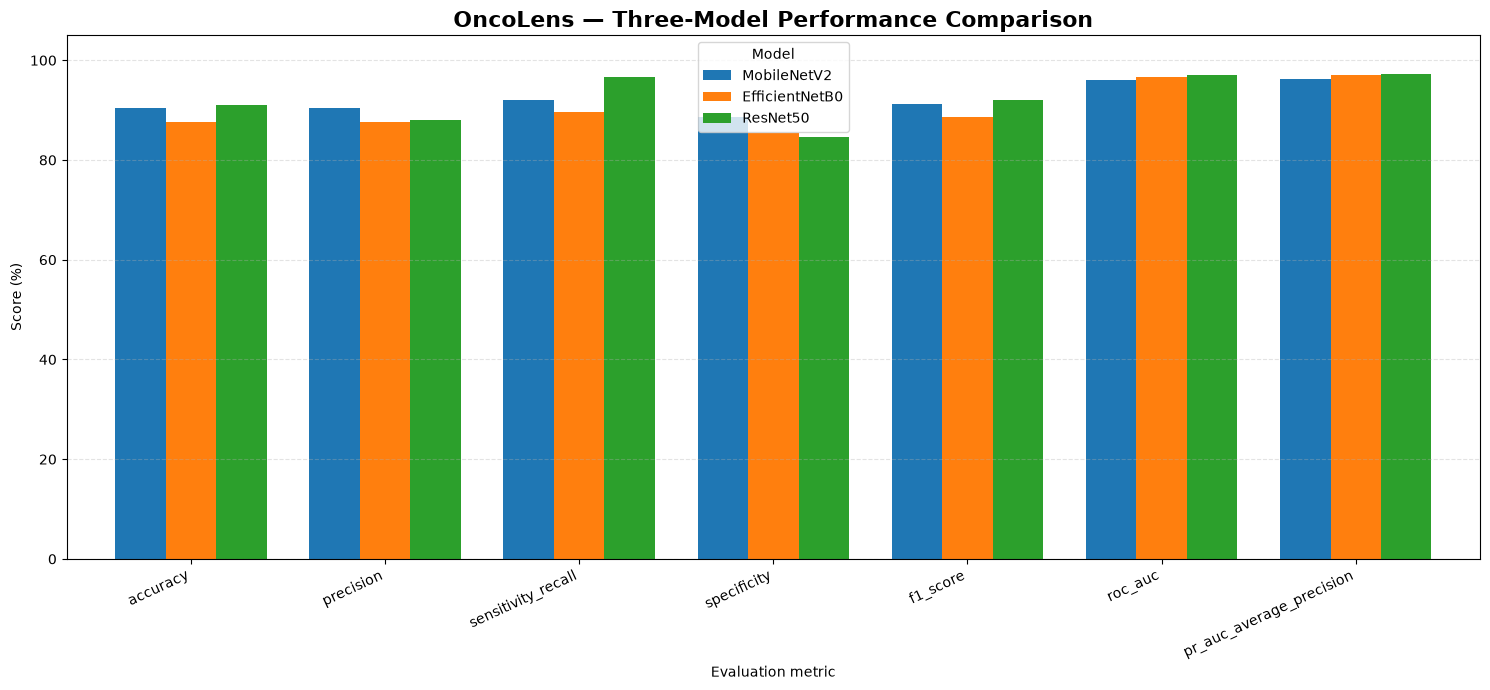

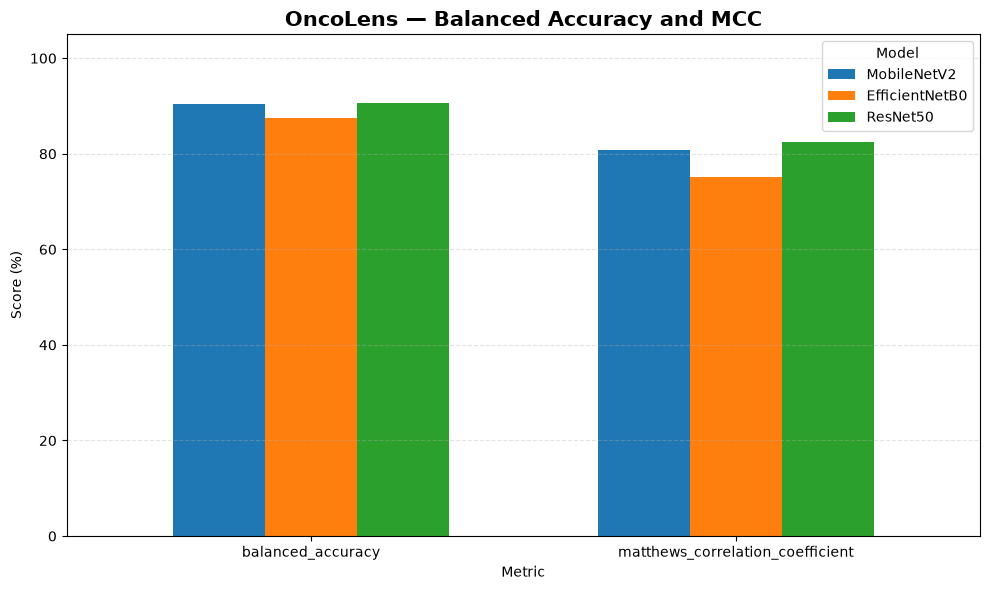

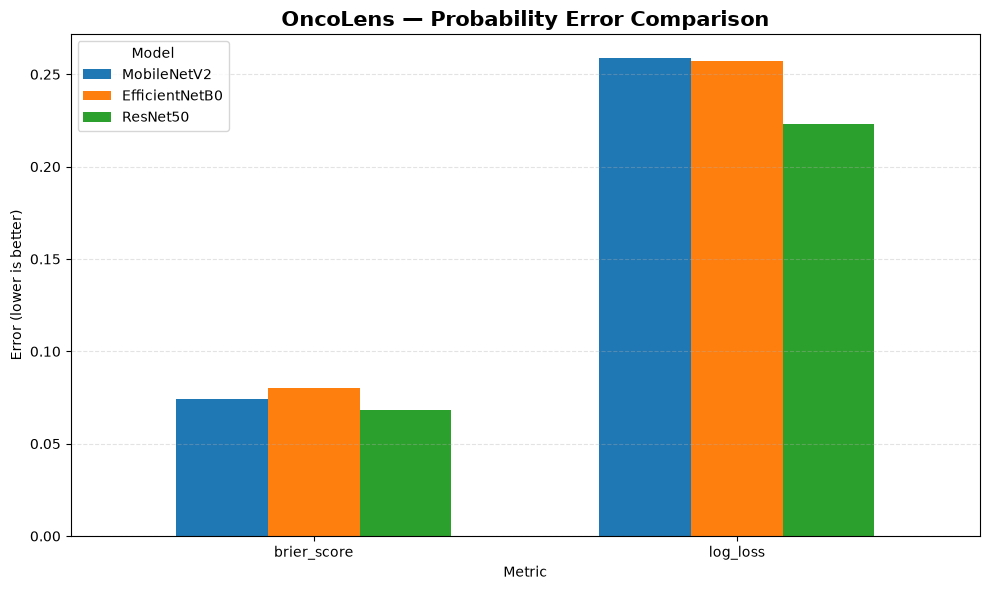

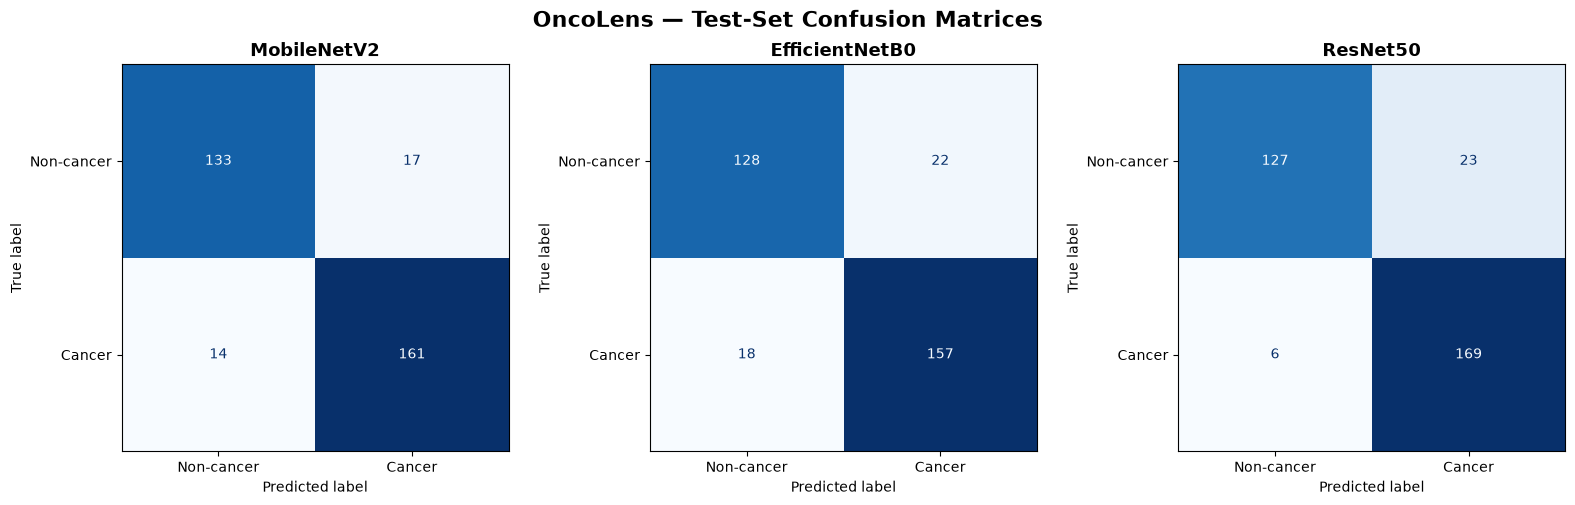

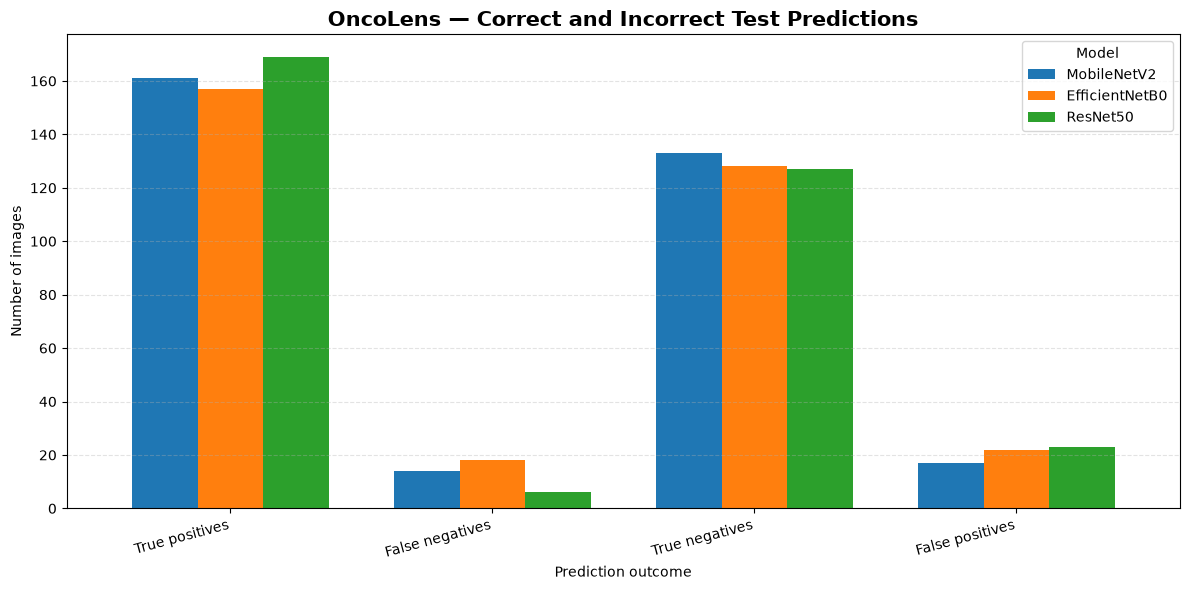


ONCOLENS — ALL COMPARISON OUTPUTS SAVED

Metrics table:
c:\Users\Bhavana BV\Downloads\OncoLens\results\final_model_comparison\three_model_comparison.csv

Metric rankings:
c:\Users\Bhavana BV\Downloads\OncoLens\results\final_model_comparison\three_model_metric_rankings.csv

Prediction counts:
c:\Users\Bhavana BV\Downloads\OncoLens\results\final_model_comparison\three_model_prediction_counts.csv

Graphs folder:
c:\Users\Bhavana BV\Downloads\OncoLens\results\final_model_comparison\figures

Models compared: MobileNetV2, EfficientNetB0, ResNet50
Test images per model: 325

IMPORTANT: These are the previously reported results. The graphs do not retrain or reevaluate the models.
ROC and precision-recall curve shapes cannot be reconstructed from AUC values alone; the per-image prediction probabilities are required for those curves.

Research prototype only; not clinically validated.


In [6]:
# ================================================================
# ONCOLENS — COMPLETE THREE-MODEL COMPARISON
# MobileNetV2 vs EfficientNetB0 vs ResNet50
# ================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------

ROOT = Path.cwd()

OUTPUT = ROOT / "results" / "final_model_comparison"
FIGURES = OUTPUT / "figures"

FIGURES.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------
# 2. EXISTING REPORTED TEST RESULTS
# ------------------------------------------------
# These are the metrics you previously shared.
# All metrics are from 325 test images at threshold 0.5.

results = {
    "MobileNetV2": {
        "test_images": 325,
        "threshold": 0.5,
        "accuracy": 0.904615,
        "precision": 0.904494,
        "sensitivity_recall": 0.920000,
        "specificity": 0.886667,
        "f1_score": 0.912181,
        "roc_auc": 0.959620,
        "pr_auc_average_precision": 0.962900,
        "balanced_accuracy": 0.903333,
        "matthews_correlation_coefficient": 0.808000,
        "brier_score": 0.074440,
        "log_loss": 0.258700,
        "tn": 133,
        "fp": 17,
        "fn": 14,
        "tp": 161,
    },

    "EfficientNetB0": {
        "test_images": 325,
        "threshold": 0.5,
        "accuracy": 0.876923,
        "precision": 0.877095,
        "sensitivity_recall": 0.897143,
        "specificity": 0.853333,
        "f1_score": 0.887019,
        "roc_auc": 0.966500,
        "pr_auc_average_precision": 0.970700,
        "balanced_accuracy": 0.875238,
        "matthews_correlation_coefficient": 0.752100,
        "brier_score": 0.080300,
        "log_loss": 0.257200,
        "tn": 128,
        "fp": 22,
        "fn": 18,
        "tp": 157,
    },

    "ResNet50": {
        "test_images": 325,
        "threshold": 0.5,
        "accuracy": 0.910769,
        "precision": 0.880208,
        "sensitivity_recall": 0.965714,
        "specificity": 0.846667,
        "f1_score": 0.920981,
        "roc_auc": 0.970667,
        "pr_auc_average_precision": 0.973191,
        "balanced_accuracy": 0.906190,
        "matthews_correlation_coefficient": 0.823660,
        "brier_score": 0.068328,
        "log_loss": 0.223255,
        "tn": 127,
        "fp": 23,
        "fn": 6,
        "tp": 169,
    },
}

df = pd.DataFrame(results).T
df.index.name = "model"

# ------------------------------------------------
# 3. SAVE AND DISPLAY ALL METRICS
# ------------------------------------------------

metrics_csv = OUTPUT / "three_model_comparison.csv"
df.to_csv(metrics_csv, float_format="%.6f")

print("=" * 85)
print("ONCOLENS — COMPLETE THREE-MODEL RESULTS")
print("=" * 85)

display(df.style.format({
    "accuracy": "{:.2%}",
    "precision": "{:.2%}",
    "sensitivity_recall": "{:.2%}",
    "specificity": "{:.2%}",
    "f1_score": "{:.2%}",
    "roc_auc": "{:.2%}",
    "pr_auc_average_precision": "{:.2%}",
    "balanced_accuracy": "{:.2%}",
    "matthews_correlation_coefficient": "{:.4f}",
    "brier_score": "{:.4f}",
    "log_loss": "{:.4f}",
}))

print("\nSaved:", metrics_csv)

# ------------------------------------------------
# 4. RANK MODELS FOR EACH METRIC
# ------------------------------------------------

higher_is_better = [
    "accuracy",
    "precision",
    "sensitivity_recall",
    "specificity",
    "f1_score",
    "roc_auc",
    "pr_auc_average_precision",
    "balanced_accuracy",
    "matthews_correlation_coefficient",
]

lower_is_better = [
    "brier_score",
    "log_loss",
]

ranking_rows = []

for metric in higher_is_better:
    ranking = df[metric].rank(
        ascending=False,
        method="min"
    )

    for model in df.index:
        ranking_rows.append({
            "metric": metric,
            "model": model,
            "score": df.loc[model, metric],
            "rank": int(ranking.loc[model]),
        })

for metric in lower_is_better:
    ranking = df[metric].rank(
        ascending=True,
        method="min"
    )

    for model in df.index:
        ranking_rows.append({
            "metric": metric,
            "model": model,
            "score": df.loc[model, metric],
            "rank": int(ranking.loc[model]),
        })

ranking_df = pd.DataFrame(ranking_rows)

ranking_path = OUTPUT / "three_model_metric_rankings.csv"
ranking_df.to_csv(ranking_path, index=False)

print("\n" + "=" * 85)
print("BEST MODEL FOR EACH METRIC")
print("=" * 85)

for metric in higher_is_better + lower_is_better:
    best = (
        df[metric].idxmin()
        if metric in lower_is_better
        else df[metric].idxmax()
    )
    print(f"{metric:38s}: {best} ({df.loc[best, metric]:.4f})")

# ------------------------------------------------
# 5. MAIN PERFORMANCE COMPARISON GRAPH
# ------------------------------------------------

main_metrics = [
    "accuracy",
    "precision",
    "sensitivity_recall",
    "specificity",
    "f1_score",
    "roc_auc",
    "pr_auc_average_precision",
]

ax = (df[main_metrics].T * 100).plot(
    kind="bar",
    figsize=(15, 7),
    width=0.78
)

ax.set_title(
    "OncoLens — Three-Model Performance Comparison",
    fontsize=16,
    fontweight="bold"
)
ax.set_ylabel("Score (%)")
ax.set_xlabel("Evaluation metric")
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(title="Model")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURES / "three_model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------
# 6. BALANCED ACCURACY AND MCC GRAPH
# ------------------------------------------------

ax = (df[
    ["balanced_accuracy", "matthews_correlation_coefficient"]
].T * 100).plot(
    kind="bar",
    figsize=(10, 6),
    width=0.65
)

ax.set_title(
    "OncoLens — Balanced Accuracy and MCC",
    fontsize=15,
    fontweight="bold"
)
ax.set_ylabel("Score (%)")
ax.set_xlabel("Metric")
ax.set_ylim(0, 105)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(title="Model")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURES / "balanced_accuracy_mcc_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------
# 7. PROBABILITY ERROR GRAPH
# Lower Brier score and log loss are better.
# ------------------------------------------------

ax = df[["brier_score", "log_loss"]].T.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.65
)

ax.set_title(
    "OncoLens — Probability Error Comparison",
    fontsize=15,
    fontweight="bold"
)
ax.set_ylabel("Error (lower is better)")
ax.set_xlabel("Metric")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(title="Model")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURES / "three_model_probability_errors.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------
# 8. CONFUSION MATRICES — ALL THREE MODELS
# ------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, model_name in zip(axes, results.keys()):
    m = results[model_name]

    cm = np.array([
        [m["tn"], m["fp"]],
        [m["fn"], m["tp"]],
    ])

    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Non-cancer", "Cancer"]
    )

    display_obj.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(model_name, fontsize=13, fontweight="bold")

fig.suptitle(
    "OncoLens — Test-Set Confusion Matrices",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURES / "three_model_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------
# 9. TRUE POSITIVE / FALSE NEGATIVE COMPARISON
# ------------------------------------------------

counts = pd.DataFrame({
    model: {
        "True positives": values["tp"],
        "False negatives": values["fn"],
        "True negatives": values["tn"],
        "False positives": values["fp"],
    }
    for model, values in results.items()
})

ax = counts.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

ax.set_title(
    "OncoLens — Correct and Incorrect Test Predictions",
    fontsize=15,
    fontweight="bold"
)
ax.set_ylabel("Number of images")
ax.set_xlabel("Prediction outcome")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.legend(title="Model")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURES / "three_model_prediction_counts.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------
# 10. SAVE PREDICTION COUNTS
# ------------------------------------------------

counts_path = OUTPUT / "three_model_prediction_counts.csv"
counts.to_csv(counts_path)

print("\n" + "=" * 85)
print("ONCOLENS — ALL COMPARISON OUTPUTS SAVED")
print("=" * 85)

print("\nMetrics table:")
print(metrics_csv)

print("\nMetric rankings:")
print(ranking_path)

print("\nPrediction counts:")
print(counts_path)

print("\nGraphs folder:")
print(FIGURES)

print("\nModels compared:", ", ".join(results.keys()))
print("Test images per model: 325")

print(
    "\nIMPORTANT: These are the previously reported results. "
    "The graphs do not retrain or reevaluate the models."
)
print(
    "ROC and precision-recall curve shapes cannot be reconstructed "
    "from AUC values alone; the per-image prediction probabilities "
    "are required for those curves."
)
print(
    "\nResearch prototype only; not clinically validated."
)

In [9]:
from pathlib import Path
import pandas as pd

BASE = Path.cwd()
RESULTS = BASE / "results"

# If the notebook isn't running from the OncoLens folder, use this path:
if not RESULTS.exists():
    BASE = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")
    RESULTS = BASE / "results"

print("=" * 75)
print("ONCOLENS — RESNET50 PLOT AUDIT")
print("=" * 75)
print("Project folder:", BASE)
print("Results folder exists:", RESULTS.exists())

# 1. Inspect the original ResNet50 experiment
RESNET_DIR = RESULTS / "resnet50_experiment"

print("\n1. RESNET50 EXPERIMENT FILES")
print("-" * 75)

if RESNET_DIR.exists():
    for folder in [RESNET_DIR, RESNET_DIR / "figures",
                   RESNET_DIR / "checkpoints"]:
        if folder.exists():
            print(f"\n[{folder.relative_to(RESULTS)}]")
            files = sorted(
                p for p in folder.iterdir() if p.is_file()
            )
            if not files:
                print("  No files directly inside this folder.")
            for p in files:
                print(f"  {p.name} ({p.stat().st_size / 1024:.1f} KB)")
else:
    print("ResNet50 experiment folder not found.")

# 2. Find all plot/image files anywhere under results
IMAGE_EXTS = {".png", ".jpg", ".jpeg", ".svg", ".pdf", ".webp"}

all_plots = []
if RESULTS.exists():
    for p in RESULTS.rglob("*"):
        if (
            p.is_file()
            and p.suffix.lower() in IMAGE_EXTS
            and "ALL_MODEL_PLOTS" not in p.parts
        ):
            all_plots.append(p)

print("\n\n2. ORIGINAL PLOT FILES BY MODEL")
print("-" * 75)

groups = {
    "MobileNetV2": [],
    "EfficientNetB0": [],
    "ResNet50": [],
    "Other / Combined": []
}

for p in all_plots:
    text = str(p).lower()

    if "resnet50" in text:
        groups["ResNet50"].append(p)
    elif "mobilenetv2" in text:
        groups["MobileNetV2"].append(p)
    elif "efficientnetb0" in text:
        groups["EfficientNetB0"].append(p)
    else:
        groups["Other / Combined"].append(p)

for model, files in groups.items():
    print(f"\n{model}: {len(files)} plot/image files")
    for p in sorted(files):
        print("  -", p.relative_to(RESULTS))

# 3. Check files required for regenerating plots without retraining
print("\n\n3. RESNET50 REGENERATION INPUTS")
print("-" * 75)

required = [
    RESNET_DIR / "resnet50_final_test_metrics.csv",
    RESNET_DIR / "resnet50_final_test_metrics.json",
    RESNET_DIR / "resnet50_test_predictions.csv",
    RESNET_DIR / "resnet50_training_history.csv",
    RESNET_DIR / "checkpoints" / "resnet50_best.keras",
]

for p in required:
    print(f"{'FOUND' if p.exists() else 'MISSING'}: {p.relative_to(RESULTS)}")

print("\nAudit complete. No model training was started.")


ONCOLENS — RESNET50 PLOT AUDIT
Project folder: c:\Users\Bhavana BV\Downloads\OncoLens
Results folder exists: True

1. RESNET50 EXPERIMENT FILES
---------------------------------------------------------------------------

[resnet50_experiment]
  resnet50_final_test_metrics.csv (0.4 KB)
  resnet50_final_test_metrics.json (0.6 KB)
  resnet50_test_predictions.csv (16.6 KB)
  resnet50_training_history.csv (1.9 KB)

[resnet50_experiment\figures]
  resnet50_confusion_matrix.png (50.4 KB)
  resnet50_precision_recall_curve.png (43.4 KB)
  resnet50_roc_curve.png (63.6 KB)
  resnet50_training_loss.png (107.6 KB)

[resnet50_experiment\checkpoints]
  resnet50_best.keras (95884.5 KB)


2. ORIGINAL PLOT FILES BY MODEL
---------------------------------------------------------------------------

MobileNetV2: 64 plot/image files
  - step08_final_test\mobilenetv2_confusion_matrix.png
  - step09_final_analysis\figures\mobilenetv2_confusion_matrix.png
  - step09_gradcam\heatmaps\0000_mobilenetv2_heatmap.pn

ONCOLENS — FINAL THREE-MODEL RESULTS
Project: c:\Users\Bhavana BV\Downloads\OncoLens
Output: c:\Users\Bhavana BV\Downloads\OncoLens\results\FINAL_RESEARCH_FIGURES

FINAL TEST METRICS
---------------------------------------------------------------------------
         Model  Accuracy  Precision  Sensitivity_Recall  Specificity  F1_Score  ROC_AUC  PR_AUC  Balanced_Accuracy    MCC  Brier_Score  Log_Loss  TN  FP  FN  TP
   MobileNetV2    0.9046     0.9045              0.9200       0.8867    0.9122   0.9596  0.9629             0.9033 0.8080       0.0744    0.2587 133  17  14 161
EfficientNetB0    0.8769     0.8771              0.8971       0.8533    0.8870   0.9665  0.9707             0.8752 0.7521       0.0803    0.2572 128  22  18 157
      ResNet50    0.9108     0.8802              0.9657       0.8467    0.9210   0.9707  0.9732             0.9062 0.8237       0.0683    0.2233 127  23   6 169

METRIC RANKINGS (1 = best)
---------------------------------------------------------------------

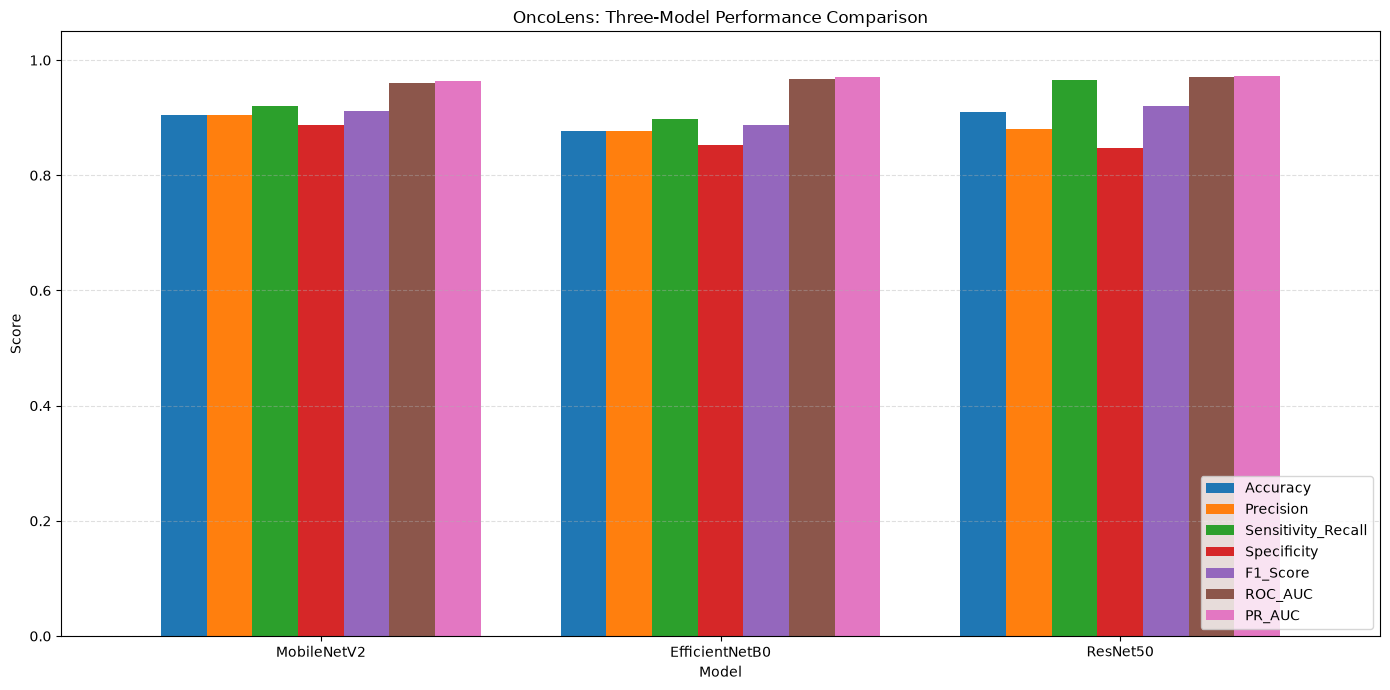

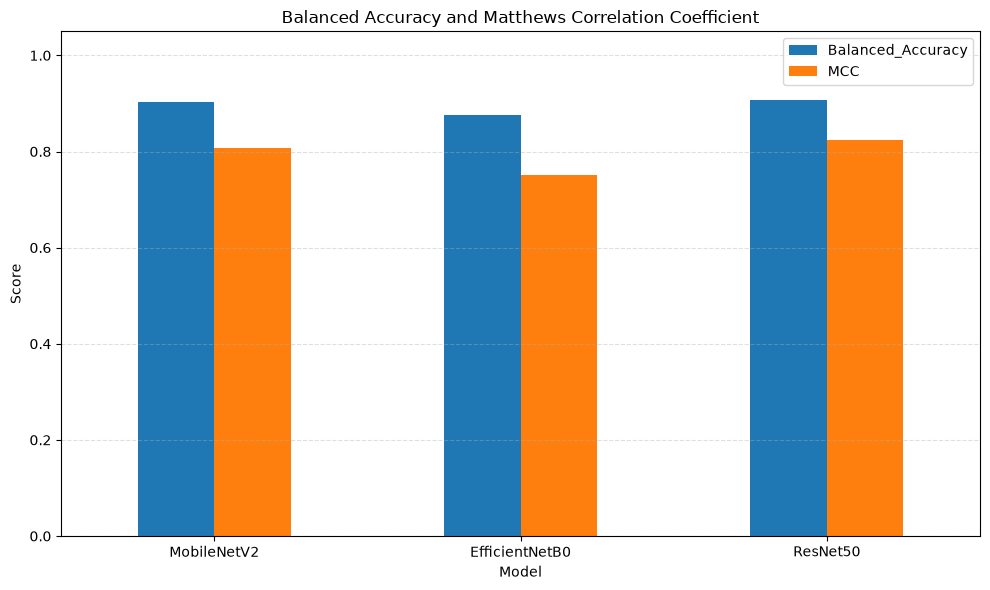

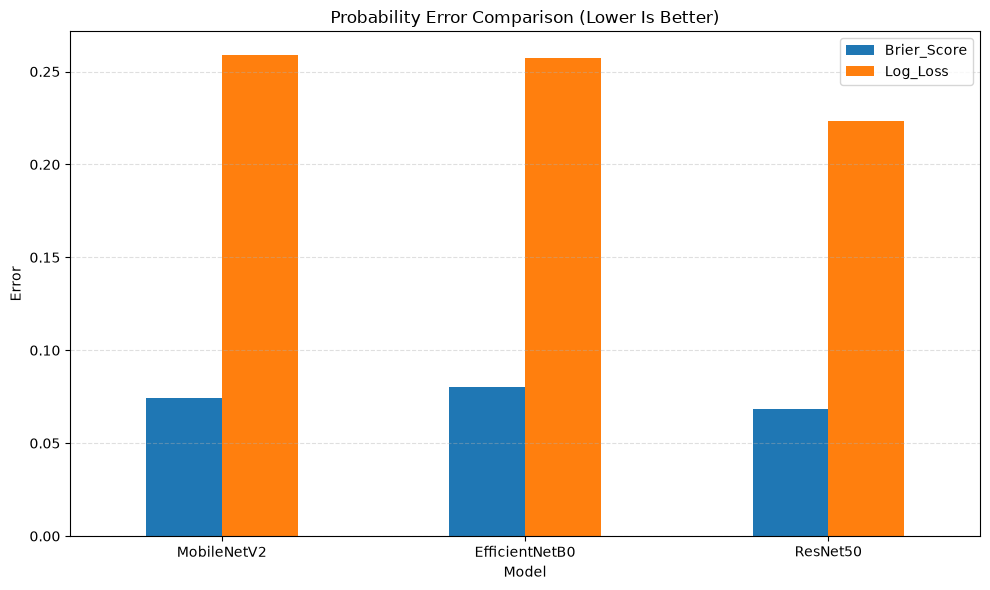

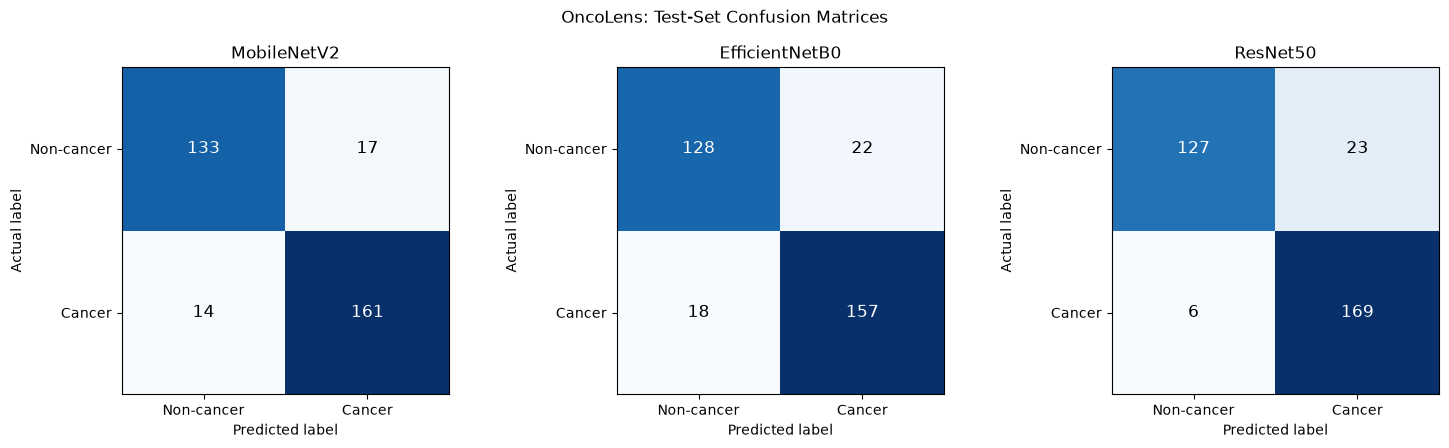


No prediction CSV located automatically for MobileNetV2.

No prediction CSV located automatically for EfficientNetB0.

Prediction file: ResNet50 -> resnet50_test_predictions.csv
Columns: ['path', 'label_binary', 'true_label', 'cancer_probability', 'predicted_label', 'threshold']


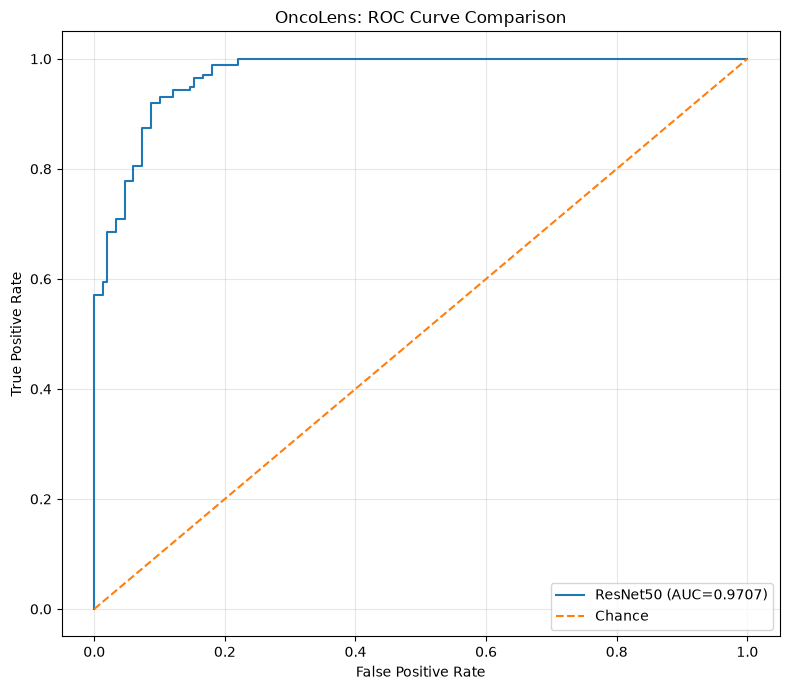

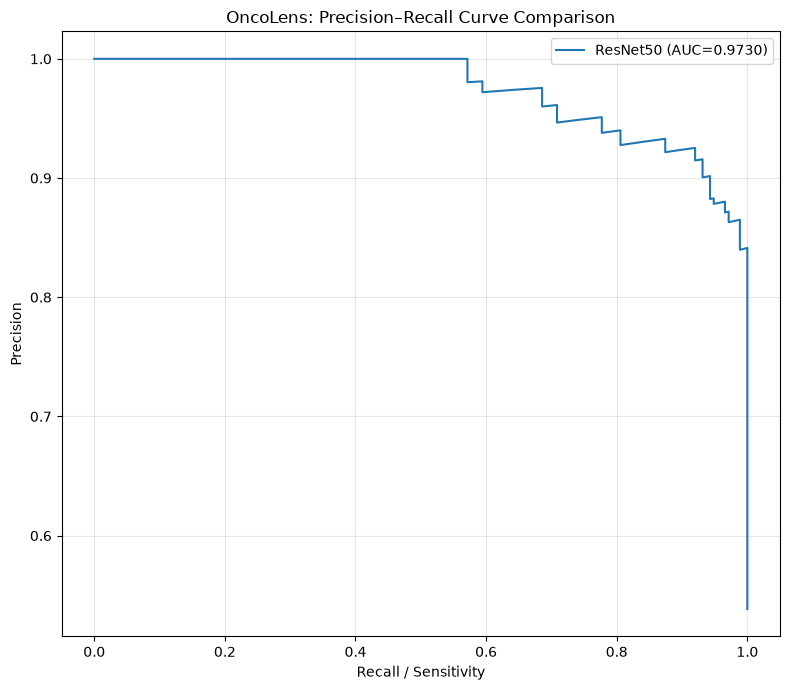


COMPLETED
Metrics CSV: c:\Users\Bhavana BV\Downloads\OncoLens\results\FINAL_RESEARCH_FIGURES\three_model_test_results.csv
Rankings CSV: c:\Users\Bhavana BV\Downloads\OncoLens\results\FINAL_RESEARCH_FIGURES\three_model_metric_rankings.csv
HTML report: c:\Users\Bhavana BV\Downloads\OncoLens\results\FINAL_RESEARCH_FIGURES\OncoLens_Three_Model_Final_Report.html
Figures folder: c:\Users\Bhavana BV\Downloads\OncoLens\results\FINAL_RESEARCH_FIGURES\figures
Models with usable prediction CSVs: ['ResNet50']

No model was retrained.


In [10]:

from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    auc
)

warnings.filterwarnings("ignore")

# ============================================================
# 1. PROJECT PATHS
# ============================================================

BASE = Path.cwd()

if not (BASE / "results").exists():
    BASE = Path(r"C:\Users\Bhavana BV\Downloads\OncoLens")

RESULTS = BASE / "results"
OUT = RESULTS / "FINAL_RESEARCH_FIGURES"
FIGURES = OUT / "figures"

OUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("ONCOLENS — FINAL THREE-MODEL RESULTS")
print("=" * 75)
print("Project:", BASE)
print("Output:", OUT)

# ============================================================
# 2. PREVIOUSLY RECORDED TEST RESULTS
# ============================================================
# These values are the previously reported results.
# They are not recalculated from predictions in this section.

metrics = pd.DataFrame([
    {
        "Model": "MobileNetV2",
        "Accuracy": 0.904615,
        "Precision": 0.904494,
        "Sensitivity_Recall": 0.920000,
        "Specificity": 0.886667,
        "F1_Score": 0.912181,
        "ROC_AUC": 0.959620,
        "PR_AUC": 0.962900,
        "Balanced_Accuracy": 0.903333,
        "MCC": 0.808000,
        "Brier_Score": 0.074440,
        "Log_Loss": 0.258700,
        "TN": 133, "FP": 17, "FN": 14, "TP": 161
    },
    {
        "Model": "EfficientNetB0",
        "Accuracy": 0.876923,
        "Precision": 0.877095,
        "Sensitivity_Recall": 0.897143,
        "Specificity": 0.853333,
        "F1_Score": 0.887019,
        "ROC_AUC": 0.966500,
        "PR_AUC": 0.970700,
        "Balanced_Accuracy": 0.875238,
        "MCC": 0.752100,
        "Brier_Score": 0.080300,
        "Log_Loss": 0.257200,
        "TN": 128, "FP": 22, "FN": 18, "TP": 157
    },
    {
        "Model": "ResNet50",
        "Accuracy": 0.910769,
        "Precision": 0.880208,
        "Sensitivity_Recall": 0.965714,
        "Specificity": 0.846667,
        "F1_Score": 0.920981,
        "ROC_AUC": 0.970667,
        "PR_AUC": 0.973191,
        "Balanced_Accuracy": 0.906190,
        "MCC": 0.823660,
        "Brier_Score": 0.068328,
        "Log_Loss": 0.223255,
        "TN": 127, "FP": 23, "FN": 6, "TP": 169
    }
])

metrics.to_csv(OUT / "three_model_test_results.csv", index=False)

print("\nFINAL TEST METRICS")
print("-" * 75)
print(metrics.round(4).to_string(index=False))

# ============================================================
# 3. RANK MODELS FOR EACH METRIC
# ============================================================

higher_is_better = [
    "Accuracy", "Precision", "Sensitivity_Recall", "Specificity",
    "F1_Score", "ROC_AUC", "PR_AUC", "Balanced_Accuracy", "MCC"
]

lower_is_better = ["Brier_Score", "Log_Loss"]

rankings = pd.DataFrame({"Model": metrics["Model"]})

for col in higher_is_better:
    rankings[col + "_Rank"] = (
        metrics[col].rank(ascending=False, method="min").astype(int)
    )

for col in lower_is_better:
    rankings[col + "_Rank"] = (
        metrics[col].rank(ascending=True, method="min").astype(int)
    )

rankings.to_csv(OUT / "three_model_metric_rankings.csv", index=False)

print("\nMETRIC RANKINGS (1 = best)")
print("-" * 75)
print(rankings.to_string(index=False))

# ============================================================
# 4. PERFORMANCE COMPARISON GRAPH
# ============================================================

performance_metrics = [
    "Accuracy", "Precision", "Sensitivity_Recall",
    "Specificity", "F1_Score", "ROC_AUC", "PR_AUC"
]

plot_df = metrics.set_index("Model")[performance_metrics]

ax = plot_df.plot(
    kind="bar",
    figsize=(14, 7),
    ylim=(0, 1.05),
    width=0.8
)

ax.set_title("OncoLens: Three-Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / "three_model_performance_comparison.png", dpi=300)
plt.show()
plt.close()

# ============================================================
# 5. BALANCED ACCURACY AND MCC
# ============================================================

ax = metrics.set_index("Model")[
    ["Balanced_Accuracy", "MCC"]
].plot(kind="bar", figsize=(10, 6), ylim=(0, 1.05))

ax.set_title("Balanced Accuracy and Matthews Correlation Coefficient")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / "balanced_accuracy_mcc.png", dpi=300)
plt.show()
plt.close()

# ============================================================
# 6. PROBABILITY ERROR METRICS
# ============================================================

ax = metrics.set_index("Model")[
    ["Brier_Score", "Log_Loss"]
].plot(kind="bar", figsize=(10, 6))

ax.set_title("Probability Error Comparison (Lower Is Better)")
ax.set_ylabel("Error")
ax.set_xlabel("Model")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES / "probability_error_comparison.png", dpi=300)
plt.show()
plt.close()

# ============================================================
# 7. CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, (_, row) in zip(axes, metrics.iterrows()):
    cm = np.array([
        [row["TN"], row["FP"]],
        [row["FN"], row["TP"]]
    ])

    ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.set_title(row["Model"])
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Non-cancer", "Cancer"])
    ax.set_yticklabels(["Non-cancer", "Cancer"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center", va="center",
                color="white" if cm[i, j] > cm.max() * 0.55 else "black",
                fontsize=12
            )

plt.suptitle("OncoLens: Test-Set Confusion Matrices")
plt.tight_layout()
plt.savefig(FIGURES / "three_model_confusion_matrices.png", dpi=300)
plt.show()
plt.close()

# ============================================================
# 8. TRUE ROC AND PRECISION-RECALL CURVES
# ============================================================
# Curves must be based on saved per-image probabilities.
# AUC values alone cannot reconstruct the actual curves.

prediction_files = {
    "MobileNetV2": [
        RESULTS / "step08_final_test" / "mobilenetv2_test_predictions.csv",
        RESULTS / "step09_final_analysis" / "mobilenetv2_test_predictions.csv"
    ],
    "EfficientNetB0": [
        RESULTS / "step08_final_test" / "efficientnetb0_test_predictions.csv",
        RESULTS / "step09_final_analysis" / "efficientnetb0_test_predictions.csv"
    ],
    "ResNet50": [
        RESULTS / "resnet50_experiment" / "resnet50_test_predictions.csv"
    ]
}

def find_column(df, candidates):
    lookup = {c.lower().strip(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    return None

curve_data = {}

for model, candidates in prediction_files.items():
    existing = [p for p in candidates if p.exists()]

    if not existing:
        print(f"\nNo prediction CSV located automatically for {model}.")
        continue

    path = existing[0]
    df = pd.read_csv(path)

    print(f"\nPrediction file: {model} -> {path.name}")
    print("Columns:", list(df.columns))

    y_col = find_column(df, [
        "y_true", "true_label", "actual_label", "label",
        "label_id", "y_test", "actual"
    ])

    p_col = find_column(df, [
        "cancer_probability", "probability", "prob",
        "y_prob", "predicted_probability", "cancer_prob",
        "positive_probability", "score"
    ])

    if y_col is None or p_col is None:
        print("Could not confidently identify true-label/probability columns.")
        continue

    y = pd.to_numeric(df[y_col], errors="coerce")
    p = pd.to_numeric(df[p_col], errors="coerce")

    valid = y.notna() & p.notna()
    y = y[valid].astype(int).to_numpy()
    p = p[valid].to_numpy()

    # Handle probabilities saved as percentages.
    if len(p) and p.max() > 1 and p.max() <= 100:
        p = p / 100.0

    if len(y) and len(np.unique(y)) == 2 and np.all((p >= 0) & (p <= 1)):
        # Assumes positive label 1 = cancer.
        curve_data[model] = (y, p)
    else:
        print("Labels/probabilities need manual inspection; skipped.")

if curve_data:
    # ROC curves
    plt.figure(figsize=(8, 7))

    for model, (y, p) in curve_data.items():
        fpr, tpr, _ = roc_curve(y, p, pos_label=1)
        curve_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{model} (AUC={curve_auc:.4f})")

    plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("OncoLens: ROC Curve Comparison")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGURES / "three_model_roc_curves.png", dpi=300)
    plt.show()
    plt.close()

    # Precision-recall curves
    plt.figure(figsize=(8, 7))

    for model, (y, p) in curve_data.items():
        precision, recall, _ = precision_recall_curve(y, p, pos_label=1)
        pr_auc = auc(recall[::-1], precision[::-1])
        plt.plot(recall, precision, label=f"{model} (AUC={pr_auc:.4f})")

    plt.xlabel("Recall / Sensitivity")
    plt.ylabel("Precision")
    plt.title("OncoLens: Precision–Recall Curve Comparison")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(FIGURES / "three_model_precision_recall_curves.png", dpi=300)
    plt.show()
    plt.close()
else:
    print(
        "\nROC/PR comparison curves were not generated because valid "
        "per-image probabilities could not be identified for any model."
    )

# ============================================================
# 9. SAVE HTML REPORT
# ============================================================

display_cols = [
    "Model", "Accuracy", "Precision", "Sensitivity_Recall",
    "Specificity", "F1_Score", "ROC_AUC", "PR_AUC",
    "Balanced_Accuracy", "MCC", "Brier_Score", "Log_Loss"
]

html = f"""
<html>
<head>
<meta charset="utf-8">
<title>OncoLens Final Three-Model Results</title>
<style>
body {{ font-family: Arial, sans-serif; margin: 30px; }}
table {{ border-collapse: collapse; width: 100%; }}
th, td {{ border: 1px solid #ccc; padding: 8px; text-align: center; }}
th {{ background: #e8eef7; }}
img {{ max-width: 100%; height: auto; margin: 15px 0; }}
.note {{ background: #fff5d6; padding: 12px; }}
</style>
</head>
<body>
<h1>OncoLens: Final Three-Model Comparison</h1>
<p>Models: MobileNetV2, EfficientNetB0, and ResNet50.</p>
<h2>Test Metrics</h2>
{metrics[display_cols].round(4).to_html(index=False)}
<h2>Confusion Matrix Counts</h2>
{metrics[['Model','TN','FP','FN','TP']].to_html(index=False)}
<h2>Performance Comparison</h2>
<img src="figures/three_model_performance_comparison.png">
<h2>Balanced Accuracy and MCC</h2>
<img src="figures/balanced_accuracy_mcc.png">
<h2>Probability Errors</h2>
<img src="figures/probability_error_comparison.png">
<h2>Confusion Matrices</h2>
<img src="figures/three_model_confusion_matrices.png">
<div class="note">
<b>Research limitation:</b> These are experimental results from the existing
project. The comparison is not necessarily a perfectly controlled architecture
comparison because preprocessing and training configurations may differ.
The models are research prototypes and are not validated for clinical diagnosis.
</div>
</body>
</html>
"""

(OUT / "OncoLens_Three_Model_Final_Report.html").write_text(
    html, encoding="utf-8"
)

print("\n" + "=" * 75)
print("COMPLETED")
print("=" * 75)
print("Metrics CSV:", OUT / "three_model_test_results.csv")
print("Rankings CSV:", OUT / "three_model_metric_rankings.csv")
print("HTML report:", OUT / "OncoLens_Three_Model_Final_Report.html")
print("Figures folder:", FIGURES)
print("Models with usable prediction CSVs:", list(curve_data.keys()))
print("\nNo model was retrained.")

